# Makine Öğrenmesi Modellerinin Karşılaştırılması

Bu çalışmada **UCI Car Evaluation** veri seti üzerinde 4 farklı sınıflandırma modeli karşılaştırılmıştır:

- **Random Forest (RF)** — Bagging tabanlı, bağımsız karar ağaçlarının oy çokluğuna dayanan algoritma
- **Gradient Boosting Machine (GBM)** — Sıralı hata düzeltmeli boosting algoritması
- **XGBoost** — Optimize edilmiş gradient boosting kütüphanesi
- **LightGBM** — Microsoft'un hızlı gradient boosting kütüphanesi

## Çalışmanın Amacı

Bu çalışmada bir arabanın **fiyat, bakım maliyeti, kapı sayısı, yolcu kapasitesi, bagaj hacmi ve güvenlik** özelliklerine göre **kabul edilebilirlik sınıfını** (`unacc`, `acc`, `good`, `vgood`) tahmin etmektir. Bu kapsamda 4 farklı sınıflandırma modeli (Random Forest, GBM, XGBoost, LightGBM) eğitilerek hem doğruluk hem de genelleme performansı açısından karşılaştırılmış, problem için en uygun modelin belirlenmesi hedeflenmiştir.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO # Dosya içeriğini bellek üzerinde bir dosya gibi okumak için StringIO kullanılır
import json
from sklearn.preprocessing import OrdinalEncoder # Kategorik verileri sıralı sayısal değerlere dönüştürür
from sklearn.model_selection import train_test_split # Veriyi eğitim ve test setlerine böler
from sklearn.metrics import classification_report, accuracy_score # Model performans metrikleri
from sklearn.model_selection import cross_val_score # Çapraz doğrulama ile model güvenilirliği ölçer
from sklearn.utils.class_weight import compute_sample_weight # Dengesiz sınıflar için ağırlık hesaplar
from sklearn.ensemble import RandomForestClassifier # Rastgele Orman — birden fazla karar ağacının oy çokluğu ile sınıflandırma
from sklearn.ensemble import GradientBoostingClassifier # GBM — ağaçları sırayla hata düzelterek güçlendirir
from xgboost import XGBClassifier # Gradient Boosting tabanlı güçlü sınıflandırma modeli
from lightgbm import LGBMClassifier # Microsoft'un hızlı Gradient Boosting kütüphanesi
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# UCI Car Evaluation veri seti — 1728 araç değerlendirmesi içerir
url = "https://raw.githubusercontent.com/retrowhiz/Car-Evaluation/refs/heads/master/car_data.csv"

In [4]:
response = requests.get(url) # CSV dosyasını URL'den indir

In [5]:
# İlk okuma: CSV'nin yapısını ve boyutunu kontrol et
# NOT: Bu okumada header=None olmadığı için ilk satır sütun adı olarak okunuyor (1727 satır)
if response.status_code == 200:
    df = pd.read_csv(StringIO(response.text))
 
    json_data = json.loads(df.to_json(orient="records")) # DataFrame → JSON formatına çevir
 
    print(f"Toplam: {len(json_data)} veri")
    print(f"Sütunlar: {list(df.columns)}")
    print("\n")
    print(df)
else:
    print(f"Request failed with status code: {response.status_code}")
    exit()

Toplam: 1727 veri
Sütunlar: ['vhigh', 'vhigh.1', '2', '2.1', 'small', 'low', 'unacc']


      vhigh vhigh.1      2   2.1  small   low  unacc
0     vhigh   vhigh      2     2  small   med  unacc
1     vhigh   vhigh      2     2  small  high  unacc
2     vhigh   vhigh      2     2    med   low  unacc
3     vhigh   vhigh      2     2    med   med  unacc
4     vhigh   vhigh      2     2    med  high  unacc
...     ...     ...    ...   ...    ...   ...    ...
1722    low     low  5more  more    med   med   good
1723    low     low  5more  more    med  high  vgood
1724    low     low  5more  more    big   low  unacc
1725    low     low  5more  more    big   med   good
1726    low     low  5more  more    big  high  vgood

[1727 rows x 7 columns]


In [6]:
# Doğru okuma: header=None → ilk satır da veri olarak okunur (1728 satır)
# names parametresi ile anlamlı sütun isimleri atanır
df = pd.read_csv(StringIO(response.text), header=None,
    names=["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety", "class"])
print(df)

     buying price price of the maintenance  doors capacity(persons)  \
0           vhigh                    vhigh      2                 2   
1           vhigh                    vhigh      2                 2   
2           vhigh                    vhigh      2                 2   
3           vhigh                    vhigh      2                 2   
4           vhigh                    vhigh      2                 2   
...           ...                      ...    ...               ...   
1723          low                      low  5more              more   
1724          low                      low  5more              more   
1725          low                      low  5more              more   
1726          low                      low  5more              more   
1727          low                      low  5more              more   

     size of luggage boot safety  class  
0                   small    low  unacc  
1                   small    med  unacc  
2                   s

In [7]:
# Tekrar eden (duplicate) satır kontrolü — aynı satırdan birden fazla varsa modeli yanıltır
print(f"Tekrar eden satır sayısı: {df.duplicated().sum()}")

Tekrar eden satır sayısı: 0


In [8]:
# Eksik veri (null/NaN) kontrolü — eksik veri varsa doldurma veya silme gerekir
print(df.isnull().sum())
print(f"\nToplam eksik veri: {df.isnull().sum().sum()}")

buying price                0
price of the maintenance    0
doors                       0
capacity(persons)           0
size of luggage boot        0
safety                      0
class                       0
dtype: int64

Toplam eksik veri: 0


In [9]:
# Kategorik veriler için: unique (benzersiz değer sayısı), top (en sık değer), freq (frekansı)
df.describe()

,buying price,price of the maintenance,doors,capacity(persons),size of luggage boot,safety,class
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


In [10]:
# doors ve persons sütunları int olarak okunuyor → OrdinalEncoder string bekler
df["doors"] = df["doors"].astype(str)
df["capacity(persons)"] = df["capacity(persons)"].astype(str)

# Ordinal sıralama: düşükten yükseğe doğru (0, 1, 2, 3...)
ordinal_mappings = [
    ["low", "med", "high", "vhigh"],     # buying: düşük fiyat(0) → çok yüksek(3)
    ["low", "med", "high", "vhigh"],     # maint: düşük bakım(0) → çok yüksek(3)
    ["2", "3", "4", "5more"],            # doors: 2 kapı(0) → 5+(3)
    ["2", "4", "more"],                  # persons: 2 kişi(0) → fazla(2)
    ["small", "med", "big"],             # lug_boot: küçük bagaj(0) → büyük(2)
    ["low", "med", "high"],              # safety: düşük güvenlik(0) → yüksek(2)
]

# OrdinalEncoder: kategorik → sıralı sayısal (sıra korunur)
encoder = OrdinalEncoder(categories=ordinal_mappings)
df[["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety"]] = encoder.fit_transform(
        df[["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety"]]
    )

# Target (hedef) sütununu doğru sıralamayla encode eder
class_mapping = {"unacc": 0, "acc": 1, "good": 2, "vgood": 3}
df["class"] = df["class"].map(class_mapping)

In [11]:
# Pearson korelasyonu: class ile her feature arasındaki doğrusal ilişki (-1 ile +1 arası)
# Pozitif → arttıkça class artar, Negatif → arttıkça class düşer
corr = df.corr()
print(corr['class'].sort_values(ascending=False))

class                       1.000000
safety                      0.439337
capacity(persons)           0.341707
size of luggage boot        0.157932
doors                       0.066057
price of the maintenance   -0.232422
buying price               -0.282750
Name: class, dtype: float64


In [12]:
# Veri tiplerini ve bellek kullanımını kontrol et
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   buying price              1728 non-null   float64
 1   price of the maintenance  1728 non-null   float64
 2   doors                     1728 non-null   float64
 3   capacity(persons)         1728 non-null   float64
 4   size of luggage boot      1728 non-null   float64
 5   safety                    1728 non-null   float64
 6   class                     1728 non-null   int64  
dtypes: float64(6), int64(1)
memory usage: 94.6 KB


In [13]:
df

,buying price,price of the maintenance,doors,capacity(persons),size of luggage boot,safety,class
0,3.0,3.0,0.0,0.0,0.0,0.0,0
1,3.0,3.0,0.0,0.0,0.0,1.0,0
2,3.0,3.0,0.0,0.0,0.0,2.0,0
3,3.0,3.0,0.0,0.0,1.0,0.0,0
4,3.0,3.0,0.0,0.0,1.0,1.0,0
...,...,...,...,...,...,...,...
1723,0.0,0.0,3.0,2.0,1.0,1.0,2
1724,0.0,0.0,3.0,2.0,1.0,2.0,3
1725,0.0,0.0,3.0,2.0,2.0,0.0,0
1726,0.0,0.0,3.0,2.0,2.0,1.0,2


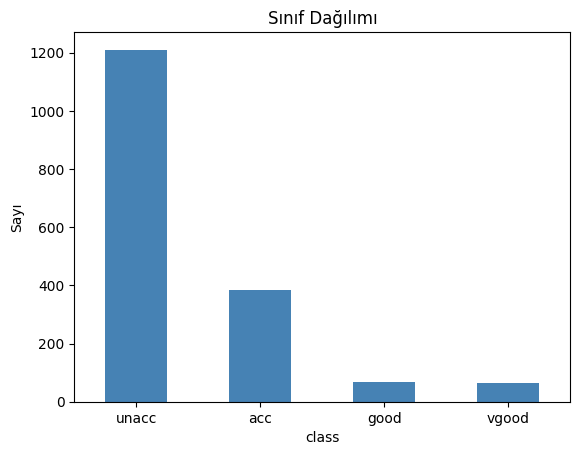

In [14]:
df["class"].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title("Sınıf Dağılımı")
plt.xticks(ticks=[0,1,2,3], labels=["unacc","acc","good","vgood"], rotation=0)
plt.ylabel("Sayı")
plt.show()

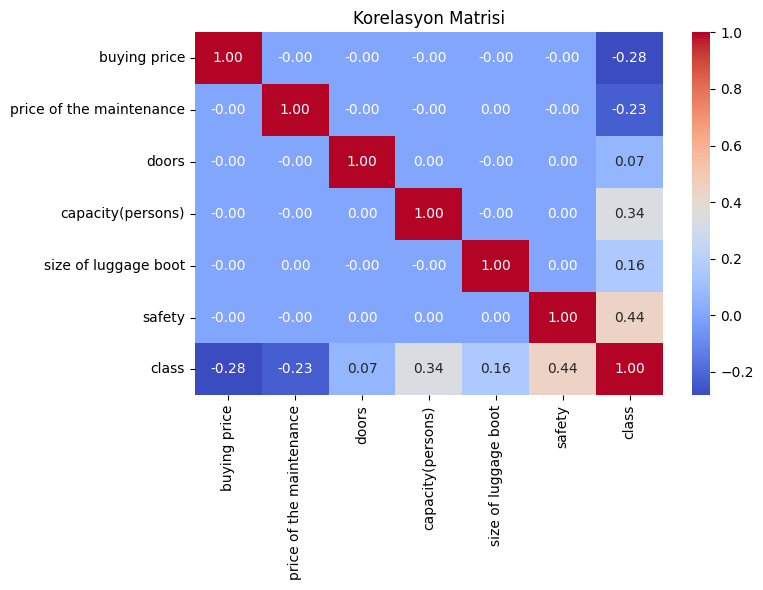

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Korelasyon Matrisi")
plt.tight_layout()
plt.show()

In [16]:
# Feature (X) ve Target (y) ayırma
X = df.drop(columns=['class']) # 6 feature: buying, maint, doors, persons, lug_boot, safety
y = df['class']                # Hedef: 4 sınıflı araç değerlendirmesi

In [17]:
# %80 eğitim, %20 test olarak böl
# stratify=y → her sette sınıf oranları korunur (unacc %70, acc %22, good %4, vgood %4)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)

In [18]:
# XGBoost modeli — Gradient Boosting: zayıf ağaçları sırayla güçlendirerek öğrenir
xgb_model = XGBClassifier(
    n_estimators=100,    # 100 ağaç kullan
    max_depth=6,         # Her ağacın maksimum derinliği
    random_state=50,     # Tekrarlanabilirlik için sabit seed
    eval_metric='mlogloss' # Çok sınıflı log-loss metriği
    # NOT: XGBoost class_weight desteklemez, bunun yerine sample_weight kullanılır
)

# Dengesiz sınıflar için ağırlık: az olan sınıfa (good/vgood) daha fazla ağırlık verir
sample_weights = compute_sample_weight('balanced', y_train)
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

# Test seti üzerinde tahmin ve performans raporu
y_pred_xgb = xgb_model.predict(X_test)
print("XGBoost Sonuçları:")
print(classification_report(y_test, y_pred_xgb,
    target_names=["unacc", "acc", "good", "vgood"]))

XGBoost Sonuçları:
              precision    recall  f1-score   support

       unacc       1.00      0.99      1.00       242
         acc       0.97      0.99      0.98        77
        good       0.93      1.00      0.97        14
       vgood       1.00      1.00      1.00        13

    accuracy                           0.99       346
   macro avg       0.98      0.99      0.99       346
weighted avg       0.99      0.99      0.99       346



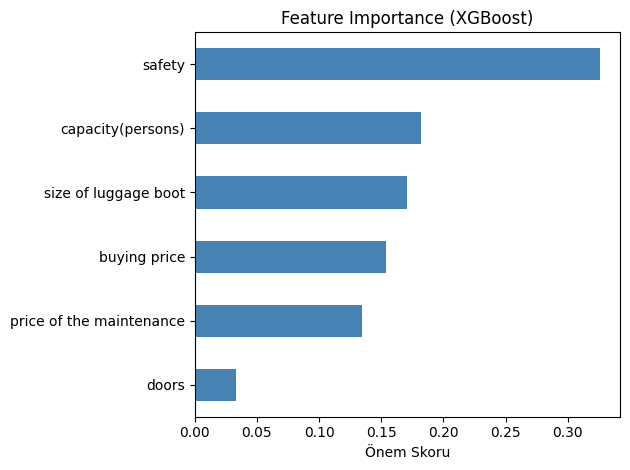

In [19]:
importances = pd.Series(xgb_model.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', color='steelblue')
plt.title("Feature Importance (XGBoost)")
plt.xlabel("Önem Skoru")
plt.tight_layout()
plt.show()

In [20]:
# Random Forest Modeli
# Birden fazla karar ağacı bağımsız eğitilir, sonuç oy çokluğu ile belirlenir (Bagging)
rf_model = RandomForestClassifier(
    n_estimators=100,          # 100 karar ağacı
    max_depth=6,               # Her ağacın maksimum derinliği
    class_weight='balanced',   # Dengesiz sınıfları dengele
    random_state=50            # Tekrarlanabilirlik
)

rf_model.fit(X_train, y_train)

# Test seti üzerinde tahmin ve performans raporu
y_pred_rf = rf_model.predict(X_test)
print("Random Forest Sonuçları:")
print(classification_report(y_test, y_pred_rf,
    target_names=["unacc", "acc", "good", "vgood"]))

Random Forest Sonuçları:
              precision    recall  f1-score   support

       unacc       1.00      0.93      0.96       242
         acc       0.80      0.90      0.85        77
        good       0.62      0.93      0.74        14
       vgood       0.93      1.00      0.96        13

    accuracy                           0.92       346
   macro avg       0.84      0.94      0.88       346
weighted avg       0.94      0.92      0.93       346



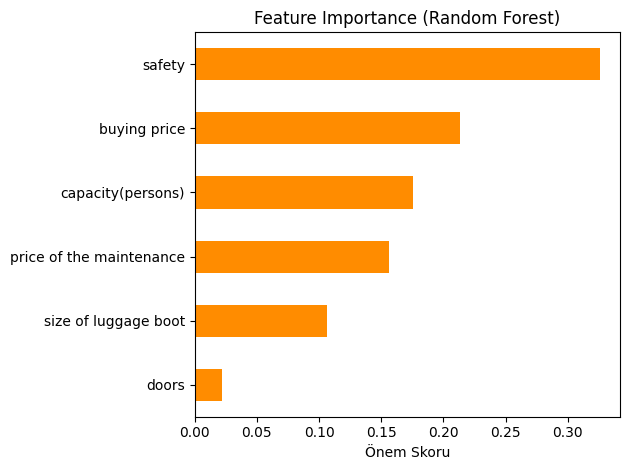

In [21]:
# Random Forest Feature Importance
rf_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
rf_importances.sort_values().plot(kind='barh', color='darkorange')
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Önem Skoru")
plt.tight_layout()
plt.show()

In [22]:
# Gradient Boosting Machine (GBM) Modeli 
# Sklearn'in klasik GBM'i — ağaçları sırayla eğitir, her ağaç öncekinin hatasını düzeltir
gbm_model = GradientBoostingClassifier(
    n_estimators=100,          # 100 ağaç
    max_depth=6,               # Her ağacın maksimum derinliği
    learning_rate=0.1,         # Öğrenme oranı
    random_state=50            # Tekrarlanabilirlik
)

# NOT: GradientBoostingClassifier sample_weight destekler
gbm_model.fit(X_train, y_train, sample_weight=sample_weights)

# Test seti üzerinde tahmin ve performans raporu
y_pred_gbm = gbm_model.predict(X_test)
print("GBM (Gradient Boosting Machine) Sonuçları:")
print(classification_report(y_test, y_pred_gbm,
    target_names=["unacc", "acc", "good", "vgood"]))

GBM (Gradient Boosting Machine) Sonuçları:
              precision    recall  f1-score   support

       unacc       1.00      1.00      1.00       242
         acc       0.99      0.99      0.99        77
        good       0.93      1.00      0.97        14
       vgood       1.00      1.00      1.00        13

    accuracy                           0.99       346
   macro avg       0.98      1.00      0.99       346
weighted avg       0.99      0.99      0.99       346



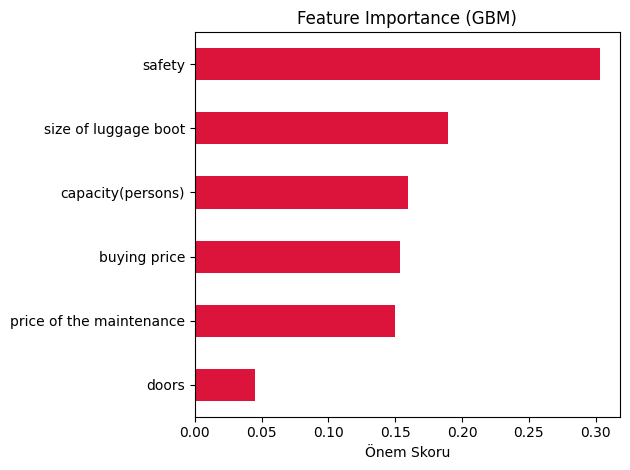

In [23]:
# GBM Feature Importance
gbm_importances = pd.Series(gbm_model.feature_importances_, index=X.columns)
gbm_importances.sort_values().plot(kind='barh', color='crimson')
plt.title("Feature Importance (GBM)")
plt.xlabel("Önem Skoru")
plt.tight_layout()
plt.show()

In [24]:
# LightGBM Modeli
# Microsoft'un geliştirdiği Gradient Boosting kütüphanesi — XGBoost'tan daha hızlı
lgbm_model = LGBMClassifier(
    objective='multiclass',
    n_estimators=100,          # 100 ağaç kullan
    max_depth=4,               # Her ağacın maksimum derinliği
    class_weight='balanced',   # Dengesiz sınıfları dengele (XGBoost'tan farklı olarak doğrudan destekler)
    random_state=50,           # Tekrarlanabilirlik
    learning_rate=0.1,
    verbose=-1                 # Eğitim loglarını gizle
)

lgbm_model.fit(X_train, y_train)

# Test seti üzerinde tahmin ve performans raporu
y_pred_lgbm = lgbm_model.predict(X_test)
print("LightGBM Sonuçları:")
print(classification_report(y_test, y_pred_lgbm,
    target_names=["unacc", "acc", "good", "vgood"]))

LightGBM Sonuçları:
              precision    recall  f1-score   support

       unacc       1.00      0.98      0.99       242
         acc       0.94      0.99      0.96        77
        good       0.93      1.00      0.97        14
       vgood       1.00      1.00      1.00        13

    accuracy                           0.98       346
   macro avg       0.97      0.99      0.98       346
weighted avg       0.98      0.98      0.98       346



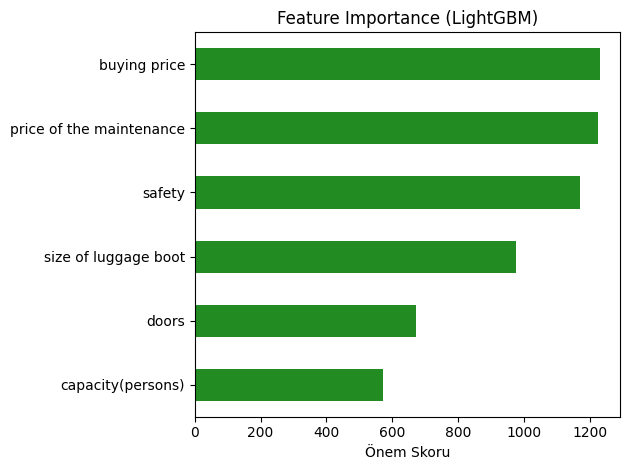

In [25]:
# LightGBM Feature Importance
lgbm_importances = pd.Series(lgbm_model.feature_importances_, index=X.columns)
lgbm_importances.sort_values().plot(kind='barh', color='forestgreen')
plt.title("Feature Importance (LightGBM)")
plt.xlabel("Önem Skoru")
plt.tight_layout()
plt.show()

      RF vs GBM vs XGBoost vs LGBM KARŞILAŞTIRMA
Metrik                    RF              GBM             XGBoost         LightGBM       
------------------------------------------------------------------------------------------
Test Accuracy             0.9249          0.9942          0.9913          0.9827         
CV Accuracy (mean)        0.8420          0.8438          0.8496          0.8542         
CV Accuracy (std)         ±0.0256         ±0.0427         ±0.0373         ±0.0260        
------------------------------------------------------------------------------------------

✅ En iyi model (CV): LightGBM — Accuracy: 0.8542


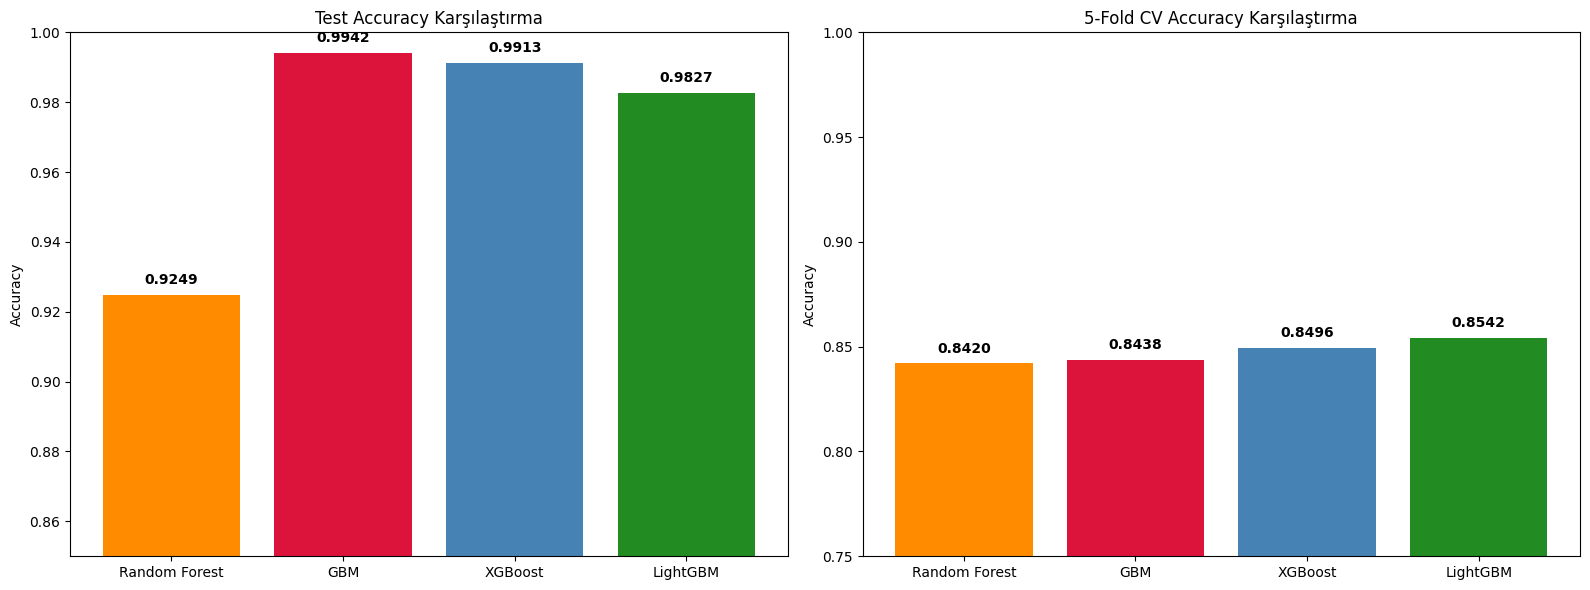

In [26]:
# Model Karşılaştırma: RF vs GBM vs XGBoost vs LightGBM
# 5-Fold Cross Validation ile her modelin gerçek performansını ölç
rf_cv = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
gbm_cv = cross_val_score(gbm_model, X, y, cv=5, scoring='accuracy')
xgb_cv = cross_val_score(xgb_model, X, y, cv=5, scoring='accuracy')
lgbm_cv = cross_val_score(lgbm_model, X, y, cv=5, scoring='accuracy')

print("      RF vs GBM vs XGBoost vs LGBM KARŞILAŞTIRMA")
print("=" * 90)
print(f"{'Metrik':<25} {'RF':<15} {'GBM':<15} {'XGBoost':<15} {'LightGBM':<15}")
print("-" * 90)
print(f"{'Test Accuracy':<25} {accuracy_score(y_test, y_pred_rf):<15.4f} "
      f"{accuracy_score(y_test, y_pred_gbm):<15.4f} "
      f"{accuracy_score(y_test, y_pred_xgb):<15.4f} "
      f"{accuracy_score(y_test, y_pred_lgbm):<15.4f}")

print(f"{'CV Accuracy (mean)':<25} {rf_cv.mean():<15.4f} "
      f"{gbm_cv.mean():<15.4f} "
      f"{xgb_cv.mean():<15.4f} "
      f"{lgbm_cv.mean():<15.4f}")

print(f"{'CV Accuracy (std)':<25} ±{rf_cv.std():<14.4f} "
      f"±{gbm_cv.std():<14.4f} "
      f"±{xgb_cv.std():<14.4f} "
      f"±{lgbm_cv.std():<14.4f}")
print("-" * 90)

# En iyi modeli bul (CV Mean skoruna göre)
cv_results = {
    "Random Forest": rf_cv.mean(),
    "GBM": gbm_cv.mean(),
    "XGBoost": xgb_cv.mean(),
    "LightGBM": lgbm_cv.mean()
}
best_model = max(cv_results, key=cv_results.get)
print(f"\n✅ En iyi model (CV): {best_model} — Accuracy: {cv_results[best_model]:.4f}")

# Görsel karşılaştırma: Bar chart
model_names = ["Random Forest", "GBM", "XGBoost", "LightGBM"]
test_accs = [
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test, y_pred_gbm),
    accuracy_score(y_test, y_pred_xgb),
    accuracy_score(y_test, y_pred_lgbm)
]
cv_accs = [rf_cv.mean(), gbm_cv.mean(), xgb_cv.mean(), lgbm_cv.mean()]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Renk paleti (4 model için)
colors = ['darkorange', 'crimson', 'steelblue', 'forestgreen']

# Test Accuracy karşılaştırma
axes[0].bar(model_names, test_accs, color=colors)
axes[0].set_title("Test Accuracy Karşılaştırma")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.85, 1.0)
for i, v in enumerate(test_accs):
    axes[0].text(i, v + 0.003, f"{v:.4f}", ha='center', fontweight='bold')

# CV Accuracy karşılaştırma
axes[1].bar(model_names, cv_accs, color=colors)
axes[1].set_title("5-Fold CV Accuracy Karşılaştırma")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.75, 1.0)
for i, v in enumerate(cv_accs):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [27]:
# MODEL KARŞILAŞTIRMASI
#
# TEST ACCURACY (tek bölme):
#   GBM (0.9942) > XGBoost (0.9913) > LightGBM (0.9827) > RF (0.9249)
#   Boosting modelleri sıralı hata düzeltme sayesinde RF'i geride bırakmıştır.
#   RF bagging tabanlı olduğu için sıralı öğrenme yok, bu yüzden daha düşüktür.
#
# CV ACCURACY (5-fold, gerçek performans):
#   LightGBM (0.8542) > XGBoost (0.8496) > GBM (0.8438) > RF (0.8420)
#   Test accuracy'de 1. olan GBM, CV'de sona düşmüştür.
#   Bu fark OVERFITTING'in göstergesidir.
#   CV her zaman daha güvenilir bir metriktir.
#
# STANDART SAPMA (kararlılık):
#   RF (±0.0256) ve LightGBM (±0.0260) modelleri en kararlı modellerdir.(fold'lar arası dalgalanma az).
#   GBM (±0.0427) en oynak model olup bazı fold'larda iyi, bazılarında kötüdür.
#
# TEST-CV FARKI:
#   GBM: 0.15  (en çok ezberleyen)
#   XGB: 0.14
#   LGBM: 0.13
#   RF: 0.08  (en az ezberleyen, en sağlıklı genelleme)
#
# SONUÇ:
#   En iyi model: LightGBM olarak görülmektedir (yüksek CV mean + düşük std).
#   GBM yüksek test accuracy gösterse de overfit yapmıştır.
#   Test accuracy tek başına yanıltıcıdır, CV ile birlikte değerlendirilmelidir.

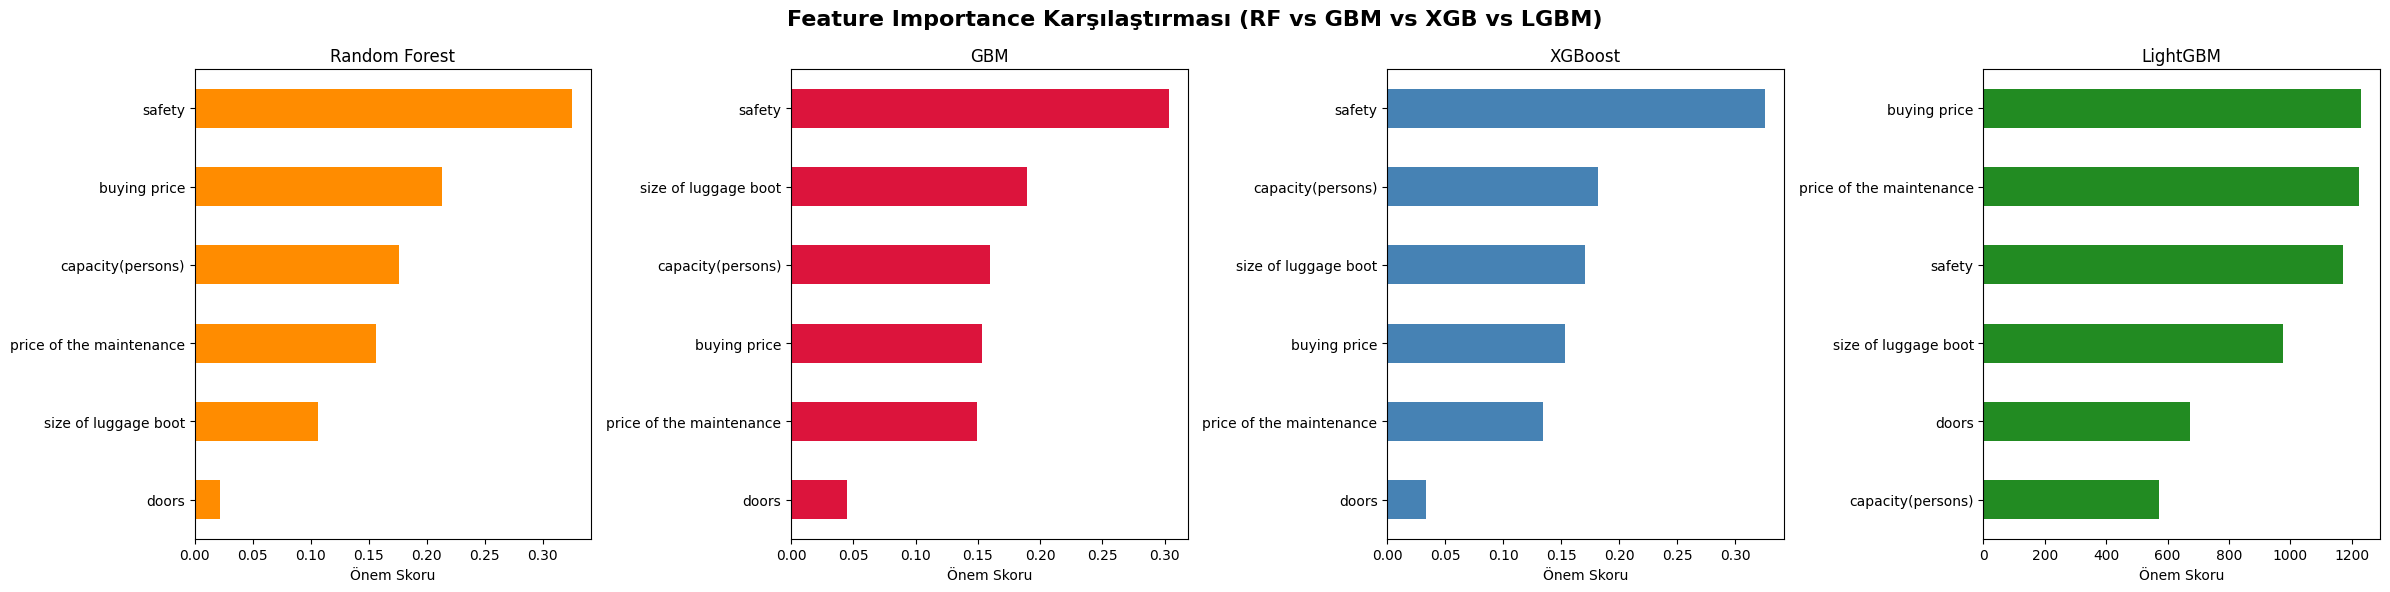

In [28]:
# Feature Importance Karşılaştırması
fig, axes = plt.subplots(1, 4, figsize=(24, 6))

# Random Forest
rf_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
rf_imp.plot(kind='barh', ax=axes[0], color='darkorange')
axes[0].set_title("Random Forest")
axes[0].set_xlabel("Önem Skoru")

# GBM
gbm_imp = pd.Series(gbm_model.feature_importances_, index=X.columns).sort_values()
gbm_imp.plot(kind='barh', ax=axes[1], color='crimson')
axes[1].set_title("GBM")
axes[1].set_xlabel("Önem Skoru")

# XGBoost
xgb_imp = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values()
xgb_imp.plot(kind='barh', ax=axes[2], color='steelblue')
axes[2].set_title("XGBoost")
axes[2].set_xlabel("Önem Skoru")

# LightGBMe
lgbm_imp = pd.Series(lgbm_model.feature_importances_, index=X.columns).sort_values()
lgbm_imp.plot(kind='barh', ax=axes[3], color='forestgreen')
axes[3].set_title("LightGBM")
axes[3].set_xlabel("Önem Skoru")

plt.suptitle("Feature Importance Karşılaştırması (RF vs GBM vs XGB vs LGBM)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
# FEATURE IMPORTANCE KARŞILAŞTIRMASI
#
# RANDOM FOREST: safety > buying > capacity > maintenance > lug_boot > doors
#   - Bagging gereği her ağaç farklı feature subseti kullanıyor.
#   - Önem yükü 6 feature'a dengeli dağılmıştır.
#
# GBM: safety > lug_boot > capacity > buying > maintenance > doors
#   lug_boot ikinci sıradadır.
#   GBM friedman_mse ile sıralı eğitimde bu featurea göre daha çok yaslanmıştır.
#
# XGBOOST: safety > capacity > lug_boot > buying > maintenance > doors
#   Korelasyon matrisindeki sıralamaya EN YAKIN sonuçtur.
#   "Gain" metriği kaliteli split'leri ödüllendirir.
#
# LIGHTGBM: buying > maintenance > safety > lug_boot > doors > capacity
#   Skor ekseni 0–1200 (diğerleri 0–0.35).
#   LightGBM varsayılan olarak "split count" kullanır yani kaç kez split'te kullanıldığını sayar.
#   capacity en sonda çünkü sadece 3 değer almaktadır.
#   buying/maintenance 4 değer alıyor → daha çok split → daha "önemli" gözüküyor.
#
# ORTAK SONUÇ:
#   3 model (RF, GBM, XGB) safety'yi 1. sıraya koymaktadır.
#   capacity ve fiyat değişkenleri de tutarlı şekilde üst sıralarda bulunmaktadır.
#   doors her modelde en az önemli değişkendir yani kapı sayısı araba değerlendirmesinde belirleyici bir değişken değildir.


In [30]:
# Örnek tahmin: Yeni bir araba değerlendirme
# buying=high(2), maint=med(1), doors=4(2), persons=more(2), lug_boot=big(2), safety=high(2)
yeni_araba = [[2, 1, 2, 2, 2, 2]]

tahmin = xgb_model.predict(yeni_araba)
sinif_isimleri = {0: "unacc", 1: "acc", 2: "good", 3: "vgood"}

print(f"XGBoost Tahmin: {sinif_isimleri[tahmin[0]]}")

XGBoost Tahmin: acc


In [31]:
# LightGBM ile aynı arabayı tahmin et
# buying=high(2), maint=med(1), doors=4(2), persons=more(2), lug_boot=big(2), safety=high(2)
yeni_araba = pd.DataFrame([[2, 1, 2, 2, 2, 2]],
    columns=["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety"])

tahmin_lgbm = lgbm_model.predict(yeni_araba)
sinif_isimleri = {0: "unacc", 1: "acc", 2: "good", 3: "vgood"}

print(f"LightGBM Tahmin: {sinif_isimleri[tahmin_lgbm[0]]}")

LightGBM Tahmin: acc


In [32]:
# GBM ile aynı arabayı tahmin et
# buying=high(2), maint=med(1), doors=4(2), persons=more(2), lug_boot=big(2), safety=high(2)
yeni_araba = pd.DataFrame([[2, 1, 2, 2, 2, 2]],
    columns=["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety"])

tahmin_gbm = gbm_model.predict(yeni_araba)
sinif_isimleri = {0: "unacc", 1: "acc", 2: "good", 3: "vgood"}

print(f"GBM Tahmin: {sinif_isimleri[tahmin_gbm[0]]}")

GBM Tahmin: acc


In [33]:
# Random Forest ile aynı arabayı tahmin et
# buying=high(2), maint=med(1), doors=4(2), persons=more(2), lug_boot=big(2), safety=high(2)
yeni_araba = pd.DataFrame([[2, 1, 2, 2, 2, 2]],
    columns=["buying price", "price of the maintenance", "doors", "capacity(persons)", "size of luggage boot", "safety"])

tahmin_rf = rf_model.predict(yeni_araba)
sinif_isimleri = {0: "unacc", 1: "acc", 2: "good", 3: "vgood"}

print(f"Random Forest Tahmin: {sinif_isimleri[tahmin_rf[0]]}")

Random Forest Tahmin: acc


## Sonuç

Bu çalışmada UCI Car Evaluation veri seti üzerinde Random Forest, GBM, XGBoost ve LightGBM modelleri karşılaştırılmıştır. Test accuracy değerlerine bakıldığında GBM (%99.42) ve XGBoost (%99.13) en yüksek skoru elde etmiş ancak 5-Fold Cross Validation sonuçlarına göre **LightGBM** (%85.42 ortalama, ±0.026 standart sapma) hem yüksek doğruluk hem de düşük varyans ile en kararlı ve genellenebilir model olarak öne çıkmıştır. GBM'in test ile CV skorları arasındaki büyük fark (~0.15) **overfitting** olduğunu göstermekte, bu da test accuracy'nin tek başına yeterli bir metrik olmadığını kanıtlamaktadır.

Feature importance analizine göre **güvenlik (safety)**, **yolcu kapasitesi (persons)** ve **fiyat (buying)** değişkenleri araç değerlendirmesinde en belirleyici faktörlerdir. **Kapı sayısı (doors)** ise tüm modellerde en az önemli değişken olarak tespit edilmiştir. Bu sonuç bir aracın kabul edilebilirliğinin büyük ölçüde güvenlik ve kullanım kapasitesine bağlı olduğunu, kapı sayısı gibi yapısal özelliklerin ise tüketici tercihinde belirleyici olmadığını ortaya koymaktadır.